# 01 — Đánh giá hệ gợi ý nhà trọ (knowledge-based · MAUT · MMR)

Đề tài THS2026-66 · thiết kế `docs/specs/Recommendation.md` · ADR-021. Notebook gọi **đúng hàm của sản phẩm**
(`apps/api/app/recommend/core.py`) qua `eval/recommend_lib.py` — không cài lại công thức.

| Mục | Nội dung | Dữ liệu |
|---|---|---|
| 1 | Trọng số từ khảo sát (tính lại, đối chiếu hằng số trong code) | khảo sát thật (31 SV) |
| 2 | Vì sao không dùng cosine của thiết kế gốc | danh mục tin thật |
| 3 | So 3 hệ offline: thoả ràng buộc, ILS@10, đa dạng vị trí, độ phủ | 31 bộ tiêu chí thật × danh mục thật |
| 4 | Độ nhạy tham số thiết kế (θ, λ, co rút, trọng số ±20%) | như mục 3 |
| 5 | P@10 / NDCG@10 / Wilcoxon từ phán đoán mù (pooling) | **không thực hiện** — không thử nghiệm người dùng (quyết định 14/10/2026) |

**Riêng tư:** `survey_v2.csv` có họ tên · MSSV · email — `recommend_lib` chỉ đọc 4 cột tiêu chí. Đừng thêm ô in CSV gốc.
**Giả định:** khảo sát không lưu câu "khu học" ⇒ mục 3–4 dùng khu II cho mọi truy vấn.

In [1]:
import math, random, statistics, sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))          # eval/
import metrics as M
import recommend_lib as RL
from recommend_lib import core

pd.set_option("display.precision", 3)
FIG = Path.cwd() / "figs"; FIG.mkdir(exist_ok=True)
# Thứ tự + màu cố định cho 3 hệ (đã chạy validate_palette: PASS; xanh ngọc tương phản thấp ⇒ luôn ghi số trên cột)
SYSTEMS = ["de_xuat", "b_gia", "b_cosine"]
LABEL = {"de_xuat": "Đề xuất (MAUT+MMR)", "b_gia": "B-giá (lọc + sắp giá)", "b_cosine": "B-cosine (thiết kế gốc)"}
COLOR = {"de_xuat": "#2a78d6", "b_gia": "#eb6834", "b_cosine": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#898781", "xtick.color": "#52514e", "ytick.color": "#52514e"})

CANDS = RL.load_candidates()
QUERIES = RL.survey_queries(campus=1)
print(f"danh mục: {len(CANDS)} tin · truy vấn khảo sát: {len(QUERIES)} · thuật toán {core.ALGO_VERSION}")

danh mục: 1115 tin · truy vấn khảo sát: 31 · thuật toán maut-mmr-v1


## 1. Trọng số từ khảo sát

In [2]:
counts = RL.survey_top3_counts()
assert counts == core.SURVEY_TOP3, (counts, core.SURVEY_TOP3)   # code phải đúng số liệu
w = core.weights()
tbl = pd.DataFrame({"yếu tố": [core.FACTOR_LABELS[k] for k in w], "số SV chọn (top-3)": [counts[k] for k in w],
                    "trọng số gốc": [w[k] for k in w]}).sort_values("trọng số gốc", ascending=False)
print("'An ninh khu vực' 19/31 SV chọn — BỎ vì chưa có dữ liệu an ninh (hạn chế của đề tài).")
tbl

'An ninh khu vực' 19/31 SV chọn — BỎ vì chưa có dữ liệu an ninh (hạn chế của đề tài).


,yếu tố,số SV chọn (top-3),trọng số gốc
0,Giá thuê rẻ,20,0.270
1,Gần trường / đi lại nhanh,19,0.257
2,Giờ giấc tự do,15,0.203
3,"Tiện nghi (máy lạnh, wifi, WC riêng…)",13,0.176
4,Có chỗ để xe,6,0.081
5,Gần chợ / quán ăn,1,0.014


## 2. Vì sao không dùng cosine (Module 2 của `planning/03_ThietKe`)

Thiết kế gốc so vector SV `[ngân sách, phút mong muốn, …]` với vector phòng `[giá, phút, …]` bằng cosine. Cosine đo
**hướng**, trong khi sở thích nhà trọ **đơn điệu** (rẻ hơn, gần hơn là tốt hơn).

In [3]:
q0 = core.Query(budget=2_000_000, campus=1, max_minutes=10)
rows = [c for c in CANDS if c.minutes[1] is not None]
def cos(a, b): return sum(x*y for x, y in zip(a, b)) / (math.hypot(*a) * math.hypot(*b))
raw = [cos((q0.budget, q0.max_minutes), (c.price, c.minutes[1])) for c in rows]
print(f"cosine thô [giá, phút]: {np.mean(np.array(raw) >= 0.9999):.0%} trong {len(rows)} tin có cos ≥ 0,9999 "
      "(giá tính bằng triệu lấn át số phút ⇒ không phân biệt được tin nào)")
print("bất biến tỉ lệ: cos((2tr,10′),(4tr,20′)) =", round(cos((2e6, 10), (4e6, 20)), 4))
top = core.baseline_cosine(CANDS, q0)
print(f"cosine chuẩn hoá (B-cosine), top-10: vượt ngân sách {sum(c.price > q0.budget for c in top)}/10, "
      f"vượt 10 phút {sum(c.minutes[1] > 10 for c in top)}/10 — trong khi "
      f"{sum(RL.satisfies(c, q0) for c in CANDS)} tin thoả cả hai")

cosine thô [giá, phút]: 100% trong 1115 tin có cos ≥ 0,9999 (giá tính bằng triệu lấn át số phút ⇒ không phân biệt được tin nào)
bất biến tỉ lệ: cos((2tr,10′),(4tr,20′)) = 1.0
cosine chuẩn hoá (B-cosine), top-10: vượt ngân sách 2/10, vượt 10 phút 2/10 — trong khi 285 tin thoả cả hai


## 3. So 3 hệ offline trên 31 bộ tiêu chí thật

- **Thoả ràng buộc gốc**: tỉ lệ tin trong top-10 có giá ≤ ngân sách và phút ≤ T người dùng khai (không tính phần nới).
  Hệ đề xuất cố ý cho phép vượt ngân sách tới 20% với điểm giảm dần ⇒ không đạt 100% là thiết kế, không phải lỗi.
- **ILS@10** (Ziegler 2005): độ giống trung bình theo cặp — thấp = đa dạng; chỉ tiêu đăng ký ≤ 0,7.
- **Độ phủ**: số tin khác nhau xuất hiện trong top-10 của 31 người — B-giá đưa mọi người cùng vài phòng rẻ nhất.

In [4]:
def offline(cands, queries):
    rec = {s: defaultdict(list) for s in SYSTEMS}
    cover = {s: set() for s in SYSTEMS}
    relaxed = 0
    for q in queries:
        out = RL.run_systems(cands, q)
        relaxed += bool(core.recommend(cands, q)[1])
        for s, items in out.items():
            r = rec[s]
            r["n"].append(len(items))
            if items:
                r["sat"].append(np.mean([RL.satisfies(c, q) for c in items]))
                r["ils"].append(core.ils(items, q.budget))
                r["pts"].append(len({(round(c.lat, 4), round(c.lng, 4)) for c in items}))
            cover[s] |= {c.id for c in items}
    df = pd.DataFrame({LABEL[s]: {
        "thoả ràng buộc gốc": np.mean(rec[s]["sat"]), "ILS@10 (↓)": np.mean(rec[s]["ils"]),
        "vị trí khác nhau / 10": np.mean(rec[s]["pts"]), "cỡ danh sách TB": np.mean(rec[s]["n"]),
        "độ phủ (số tin)": len(cover[s])} for s in SYSTEMS}).T
    return df, rec, relaxed

OFF, REC, RELAXED = offline(CANDS, QUERIES)
print(f"hệ đề xuất phải nới ràng buộc ở {RELAXED}/{len(QUERIES)} truy vấn")
OFF

hệ đề xuất phải nới ràng buộc ở 0/31 truy vấn


,thoả ràng buộc gốc,ILS@10 (↓),vị trí khác nhau / 10,cỡ danh sách TB,độ phủ (số tin)
Đề xuất (MAUT+MMR),0.919,0.295,9.968,10.0,59.0
B-giá (lọc + sắp giá),1.000,0.475,8.065,10.0,19.0
B-cosine (thiết kế gốc),0.326,0.346,6.000,10.0,70.0


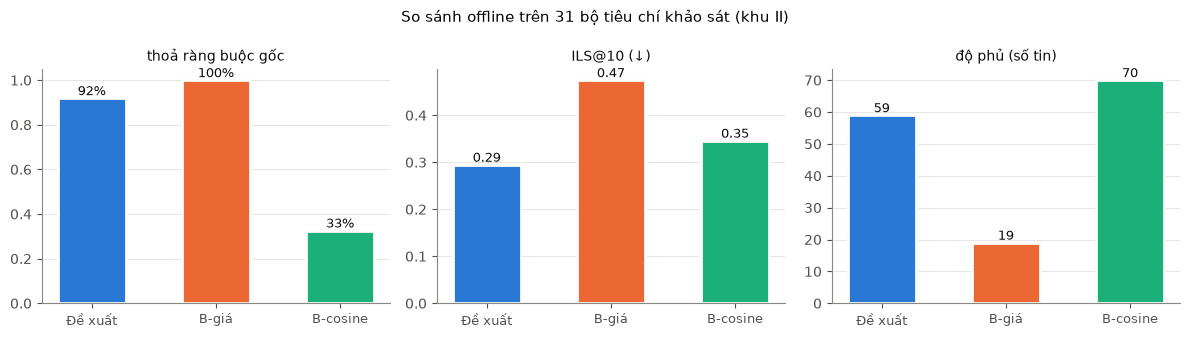

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, fmt in zip(axes, ["thoả ràng buộc gốc", "ILS@10 (↓)", "độ phủ (số tin)"], ["{:.0%}", "{:.2f}", "{:.0f}"]):
    vals = [OFF.loc[LABEL[s], col] for s in SYSTEMS]
    bars = ax.bar(range(3), vals, width=0.55, color=[COLOR[s] for s in SYSTEMS], edgecolor="#fcfcfb", linewidth=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=9, color="#0b0b0b")
    ax.set_xticks(range(3), [LABEL[s].split(" (")[0] for s in SYSTEMS], fontsize=9)
    ax.set_title(col, fontsize=10, color="#0b0b0b")
    ax.grid(axis="x", visible=False)
fig.suptitle("So sánh offline trên 31 bộ tiêu chí khảo sát (khu II)", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "01_offline_3_he.png", dpi=150); plt.show()

## 4. Độ nhạy tham số thiết kế

Các hằng số θ (điểm "chưa rõ"), λ (MMR), hệ số co rút trọng số và trọng số khảo sát ±20% **không phải số đo**. Đổi từng
cái, chạy lại 31 truy vấn, đo **Jaccard@10** giữa top-10 mới và top-10 mặc định (1 = không đổi gì).

In [6]:
BASE = {id(q): {s.c.id for s in core.recommend(CANDS, q)[0]} for q in QUERIES}

def jaccard_vs_base():
    js = []
    for q in QUERIES:
        new = {s.c.id for s in core.recommend(CANDS, q)[0]}
        old = BASE[id(q)]
        js.append(len(new & old) / len(new | old) if new | old else 1.0)
    return np.mean(js), np.min(js)

def perturb(attr, value):
    old = getattr(core, attr); setattr(core, attr, value)
    try:
        return jaccard_vs_base()
    finally:
        setattr(core, attr, old)

rows = []
for attr, vals in [("THETA", [0.3, 0.7]), ("LAMBDA", [0.5, 0.9]), ("SHRINK", [0.3, 0.7]), ("PRICE_KNEE", [0.5, 0.7])]:
    for v in vals:
        m, lo = perturb(attr, v); rows.append({"tham số": f"{attr} = {v}", "Jaccard@10 TB": m, "tệ nhất": lo})
for k in core.SURVEY_TOP3:
    for f in (0.8, 1.2):
        w = dict(core.SURVEY_TOP3); w[k] = w[k] * f
        m, lo = perturb("SURVEY_TOP3", w); rows.append({"tham số": f"w[{k}] × {f}", "Jaccard@10 TB": m, "tệ nhất": lo})
SENS = pd.DataFrame(rows)
print(f"Jaccard@10 trung bình qua mọi nhiễu: {SENS['Jaccard@10 TB'].mean():.3f}; tệ nhất 1 truy vấn: {SENS['tệ nhất'].min():.2f}")
SENS

Jaccard@10 trung bình qua mọi nhiễu: 0.850; tệ nhất 1 truy vấn: 0.18


,tham số,Jaccard@10 TB,tệ nhất
0,THETA = 0.3,0.759,0.333
1,THETA = 0.7,0.668,0.333
2,LAMBDA = 0.5,0.658,0.250
3,LAMBDA = 0.9,0.626,0.176
4,SHRINK = 0.3,0.733,0.333
5,SHRINK = 0.7,0.704,0.250
6,PRICE_KNEE = 0.5,0.845,0.333
7,PRICE_KNEE = 0.7,0.825,0.250
8,w[gia] × 0.8,0.905,0.538
9,w[gia] × 1.2,0.914,0.667


## 5. Đánh giá mù với người dùng (pooling kiểu TREC) — KHÔNG THỰC HIỆN

**Quyết định 14/10/2026 (chủ nhiệm): không tổ chức thử nghiệm với người dùng.** Mục này giữ khung tính để chạy lại được nếu
sau này có phán đoán thật (`eval/data/rec_judgments.csv` từ `app.recommend.export_judgments`); khi không có file, notebook
**không sinh dữ liệu giả** và không có số liệu ở mục này. Chỉ tiêu P@10 ≥ 0,6 / NDCG@10 ≥ 0,65 (thuyết minh bổ sung) vì vậy
chưa được đo — đánh giá hệ gợi ý dựa trên mục 1–4 (offline, dữ liệu thật).

Thiết kế buổi chấm (đã có trong sản phẩm: `/goi-y/danh-gia`, bảng `rec_eval_*`):
Mỗi SV nhập tiêu chí → server gộp top-10 của 3 hệ, xáo trộn, thẻ giống hệt nhau (không điểm/lý do) → SV chấm
0 *không quan tâm* · 1 *có thể xem thử* · 2 *sẽ liên hệ*. Mọi tin của mọi hệ đều được chấm ⇒ không có tin chưa chấm.

- **P@10 chặt**: rel = 2 · **P@10 lỏng**: rel ≥ 1 · **NDCG@10**: gain 2^rel − 1, thứ tự theo hạng của từng hệ.
- Danh sách ngắn hơn 10 (B-giá khi ít tin thoả) vẫn chia cho 10 — đúng định nghĩa P@k, phản ánh trải nghiệm bộ lọc.
- Mỗi người chỉ lấy **lượt hoàn thành đầu tiên**. So cặp bằng Wilcoxon signed-rank (`metrics.py`, có effect size r).

In [7]:
REAL = RL.JUDGMENTS_CSV.exists()
if REAL:
    J = pd.read_csv(RL.JUDGMENTS_CSV)
    J = J[J["completed"] == 1]
    first = J.groupby("rater")["session_id"].min()
    J = J[J["session_id"].isin(first.values)]
    print(f"DỮ LIỆU THẬT: {J['rater'].nunique()} người chấm, {len(J)} thẻ")
else:
    print("Không thực hiện thử nghiệm người dùng (quyết định 14/10/2026) — mục 5 không có số liệu, không sinh dữ liệu giả.")

def per_rater(J):
    out = []
    for rater, g in J.groupby("rater"):
        rel = dict(zip(g["listing_id"], g["relevance"]))
        gain = {k: 2 ** v - 1 for k, v in rel.items()}
        for s, col in zip(SYSTEMS, ["rank_proposed", "rank_price", "rank_cosine"]):
            ranked = g.dropna(subset=[col]).sort_values(col)["listing_id"].tolist()
            out.append({"rater": rater, "he": s,
                        "P@10_chat": M.precision_at_k(ranked, {k for k, v in rel.items() if v == 2}, 10),
                        "P@10_long": M.precision_at_k(ranked, {k for k, v in rel.items() if v >= 1}, 10),
                        "NDCG@10": M.ndcg_at_k(ranked, gain, 10)})
    return pd.DataFrame(out)

PR = per_rater(J) if REAL else None

def boot_ci(x, n=2000, seed=1):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    means = [rng.choice(x, len(x)).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

summary = []
for s in (SYSTEMS if REAL else []):
    g = PR[PR["he"] == s]
    row = {"hệ": LABEL[s], "N": len(g)}
    for m in ["P@10_chat", "P@10_long", "NDCG@10"]:
        lo, hi = boot_ci(g[m]); row[m] = f"{g[m].mean():.3f} [{lo:.2f}, {hi:.2f}]"
    summary.append(row)
pd.DataFrame(summary)

Không thực hiện thử nghiệm người dùng (quyết định 14/10/2026) — mục 5 không có số liệu, không sinh dữ liệu giả.


""


In [8]:
tests = []
for b in (["b_gia", "b_cosine"] if REAL else []):
    for m in ["P@10_chat", "NDCG@10"]:
        x = PR[PR["he"] == "de_xuat"].sort_values("rater")[m].tolist()
        y = PR[PR["he"] == b].sort_values("rater")[m].tolist()
        w = M.wilcoxon_signed_rank(x, y)
        tests.append({"so sánh": f"Đề xuất vs {LABEL[b]}", "chỉ số": m, **w})
pd.DataFrame(tests)

""


In [9]:
# không có phán đoán thật ⇒ không vẽ (trước 14/10 vẽ bằng dữ liệu giả)
if REAL:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    for ax, m in zip(axes, ["P@10_chat", "NDCG@10"]):
        means = [PR[PR["he"] == s][m].mean() for s in SYSTEMS]
        cis = [boot_ci(PR[PR["he"] == s][m]) for s in SYSTEMS]
        err = np.array([[mu - lo for mu, (lo, hi) in zip(means, cis)], [hi - mu for mu, (lo, hi) in zip(means, cis)]])
        bars = ax.bar(range(3), means, width=0.55, color=[COLOR[s] for s in SYSTEMS], edgecolor="#fcfcfb", linewidth=2,
                      yerr=err, error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
        for b, v in zip(bars, means):
            ax.text(b.get_x() + b.get_width() / 2, 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color="#ffffff")
        ax.set_xticks(range(3), [LABEL[s].split(" (")[0] for s in SYSTEMS], fontsize=9)
        ax.set_ylim(0, 1); ax.set_title(m + " (TB · KTC 95% bootstrap)", fontsize=10); ax.grid(axis="x", visible=False)
    fig.tight_layout(); fig.savefig(FIG / "01_online_3_he.png", dpi=150); plt.show()

## Ghi chú cho báo cáo

- Trọng số lấy từ khảo sát 31 SV (mục 1); các hằng số còn lại là thiết kế, đã kiểm độ nhạy (mục 4).
- Cosine của thiết kế gốc bị bác bằng số đo trên dữ liệu thật (mục 2–3), không bằng lập luận.
- Không thử nghiệm người dùng (quyết định 14/10/2026) ⇒ chỉ tiêu P@10 ≥ 0,6 / NDCG@10 ≥ 0,65 **chưa đo được**; nêu ở hạn chế.
  Đánh giá hệ gợi ý trong báo cáo dựa trên mục 1–4: trọng số từ khảo sát thật, so 3 hệ offline, độ nhạy.
- Hạn chế: chưa có dữ liệu an ninh; tiện ích phần lớn "chưa rõ" (tin không ghi); toạ độ cấp phường; khu học mặc định
  khu II ở offline; phút đi là ORS `driving-car`.